# Figure 4: Firm Topic Relevance and Privacy Patenting Pre- and Post-2016

| Item | Description |
|---|---|
| Goal | Construct and export Figure 4 of the proposal (Panels A, B, and C): Firm Topic Relevance and Privacy Patenting Pre- and Post-2016. |
| Input | `sample_firm_privacy_patents.csv` and `firm_topic_relevance.csv` from `X1.1 - Data for Matching and Patent Analysis`. |
| Output | Figure 4 Panels A, B, and C saved to `R - Results/R1.1 - Figures/R1.1.3 - X1 - Example of Research Enabled by LLM Pipeline/R1.1.3.1 - Figure 4 - Firm Topic Relevance and Privacy Patent Changes Pre-Post 2016`. Summary tables saved to `R - Results/R1.2 - Tables/R1.2.2 - X1 - Example of Research Enabled by LLM Pipeline/R1.2.2.2 - X1.3 - Notebooks for Analysis/Figure 4`. |
| Panels | **Panel A**: Tri-axis distribution of firm topic relevance and privacy patent intensity across quartiles.<br>**Panel B**: Pre- and Post-2016 annual patent filings by relevance quartile.<br>**Panel C**: Pre- and Post-2016 annual filings across customer data and tracking subclasses. |


## Step 1. Import packages and configure styling

Load standard data science and plotting libraries with publication styling.

In [1]:
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker
import numpy as np
import pandas as pd
from pathlib import Path
from IPython.display import Image, Markdown, display

# S3 Publication styling
plt.rcParams["font.family"] = "serif"
plt.rcParams["font.serif"] = ["Times New Roman", "DejaVu Serif", "serif"]
plt.rcParams["axes.edgecolor"] = "#333333"
plt.rcParams["axes.linewidth"] = 0.8
plt.rcParams["axes.labelcolor"] = "#111111"
plt.rcParams["xtick.color"] = "#222222"
plt.rcParams["ytick.color"] = "#222222"

FIGURE_WIDTH, FIGURE_HEIGHT = 9, 5.8
MARGIN_INCHES = 0.5 / 2.54
EXPORT_DPI = 300
THOUSANDS = ticker.StrMethodFormatter("{x:,.0f}")

# Color palette from X1.2.1
BLACK = "#000000"
BLUE = "#1E88E5"
GREY = "#5A6B7C"
CYAN = "#00ACC1"
MAROON = "#800000"
RED_ALL = "#B71C1C"

print("Setup completed successfully.")

Setup completed successfully.


## Step 2. Define file locations and group mappings

Configure paths for the topic relevance table, the patent dataset, and output directory.

In [2]:
PROJECT_FOLDER = Path.cwd().resolve().parents[1]
DATA_FOLDER = PROJECT_FOLDER / "X1 - Example of Research Enabled by LLM Pipeline/X1.1 - Data for Matching and Patent Analysis"
PATENTS_CSV = DATA_FOLDER / "sample_firm_privacy_patents.csv"
RELEVANCE_CSV = DATA_FOLDER / "firm_topic_relevance.csv"

FIGURE_FOLDER = PROJECT_FOLDER / "R - Results/R1.1 - Figures/R1.1.3 - X1 - Example of Research Enabled by LLM Pipeline/R1.1.3.1 - Figure 4 - Firm Topic Relevance and Privacy Patent Changes Pre-Post 2016"
TABLE_FOLDER = PROJECT_FOLDER / "R - Results/R1.2 - Tables/R1.2.2 - X1 - Example of Research Enabled by LLM Pipeline/R1.2.2.2 - X1.3 - Notebooks for Analysis/Figure 4"
for folder in (FIGURE_FOLDER, TABLE_FOLDER):
    folder.mkdir(parents=True, exist_ok=True)

# CPC to Topic Group Mapping
GROUP_MAPPING_5 = {
    "G06Q30/0269": "Tracking User Profiles and Data",
    "G06Q30/0255": "Tracking User Profiles and Data",
    "G06Q30/0261": "Tracking User Profiles and Data",
    "H04W12/02":   "Protecting Privacy and Anonymity (PII)",
    "G06F21/6254": "Anonymizing or Decorrelating Data",
    "H04W12/033":  "Anonymizing or Decorrelating Data",
    "H04W12/03":   "Protecting Confidentiality (Encryption)",
    "H04L67/535":  "Tracking User Activity",
}

ORDER_5 = [
    "Tracking User Profiles and Data",
    "Protecting Privacy and Anonymity (PII)",
    "Anonymizing or Decorrelating Data",
    "Protecting Confidentiality (Encryption)",
    "Tracking User Activity",
]

LABELS_5 = [
    "Tracking User Profiles and Data (G06Q 30/0269, 30/0255, 30/0261)",
    "Protecting Privacy and Anonymity (PII) (H04W 12/02)",
    "Anonymizing or Decorrelating Data (G06F 21/6254, H04W 12/033)",
    "Protecting Confidentiality by Encryption (H04W 12/03)",
    "Tracking User Activity (H04L 67/535)",
]

COLORS_5 = [BLACK, BLUE, GREY, CYAN, MAROON]
MARKERS_5 = ["o", "s", "^", "D", "v"]
STYLES_5 = ["-", "--", "-.", ":", (0, (3, 1, 1, 1))]

print(f"Data files:\n - {RELEVANCE_CSV}\n - {PATENTS_CSV}\nFigures: {FIGURE_FOLDER}\nTables: {TABLE_FOLDER}")


Data files:
 - /Users/milanmiric/Documents/Research/Active Papers/LLM Text Sumarization and Data Extraction/X1 - Example of Research Enabled by LLM Pipeline/X1.1 - Data for Matching and Patent Analysis/firm_topic_relevance.csv
 - /Users/milanmiric/Documents/Research/Active Papers/LLM Text Sumarization and Data Extraction/X1 - Example of Research Enabled by LLM Pipeline/X1.1 - Data for Matching and Patent Analysis/sample_firm_privacy_patents.csv
Figures: /Users/milanmiric/Documents/Research/Active Papers/LLM Text Sumarization and Data Extraction/R - Results/R1.1 - Figures/R1.1.3 - X1 - Example of Research Enabled by LLM Pipeline/R1.1.3.1 - Figure 4 - Firm Topic Relevance and Privacy Patent Changes Pre-Post 2016
Tables: /Users/milanmiric/Documents/Research/Active Papers/LLM Text Sumarization and Data Extraction/R - Results/R1.2 - Tables/R1.2.2 - X1 - Example of Research Enabled by LLM Pipeline/R1.2.2.2 - X1.3 - Notebooks for Analysis/Figure 4


## Step 3. Load datasets and construct firm-level privacy patent counts

Load the 1,058 sample firms with their topic relevance scores (`cosine_policy_summary_firm_summary`), partition into quartiles ($Q_1$ to $Q_4$) and deciles ($D_1$ to $D_{10}$), and merge distinct patent counts for broad privacy patents and each narrow group.

In [3]:
# Load relevance
df_relevance = pd.read_csv(RELEVANCE_CSV)
assert len(df_relevance) == 1058, f"Expected 1,058 firms, got {len(df_relevance)}"

# Construct topic relevance quartiles
df_relevance["quartile"] = pd.qcut(
    df_relevance["cosine_policy_summary_firm_summary"],
    q=4,
    labels=["Q1 (Lowest Relevance)", "Q2", "Q3", "Q4 (Highest Relevance)"]
)
q_bounds = [df_relevance["cosine_policy_summary_firm_summary"].min()] + list(
    df_relevance.groupby("quartile", observed=False)["cosine_policy_summary_firm_summary"].max()
)

# Construct topic relevance deciles
df_relevance["decile"] = pd.qcut(
    df_relevance["cosine_policy_summary_firm_summary"],
    q=10,
    labels=[f"D{i}" for i in range(1, 11)]
)

# Load patent dataset
df_patents = pd.read_csv(PATENTS_CSV)
df_patents["filing_date"] = pd.to_datetime(df_patents["filing_date"])
df_patents["filing_year"] = df_patents["filing_date"].dt.year

# 1. Broad definition: Any privacy patent
all_firm_pats = df_patents.groupby("gvkey")["patent_num"].nunique().rename("patents_broad_all")

# 2. Narrow groups
g1_pats = df_patents[df_patents["privacy_cpc"].isin(["G06Q30/0269", "G06Q30/0255", "G06Q30/0261"])].groupby("gvkey")["patent_num"].nunique().rename("patents_group_1")
g2_pats = df_patents[df_patents["privacy_cpc"] == "H04W12/02"].groupby("gvkey")["patent_num"].nunique().rename("patents_group_2")
g3_pats = df_patents[df_patents["privacy_cpc"].isin(["G06F21/6254", "H04W12/033"])].groupby("gvkey")["patent_num"].nunique().rename("patents_group_3")
g4_pats = df_patents[df_patents["privacy_cpc"] == "H04W12/03"].groupby("gvkey")["patent_num"].nunique().rename("patents_group_4")
g5_pats = df_patents[df_patents["privacy_cpc"] == "H04L67/535"].groupby("gvkey")["patent_num"].nunique().rename("patents_group_5")

# Combined data and customer tracking patents (G06Q + H04L 67/535)
track_comb_pats = df_patents[df_patents["privacy_cpc"].isin(["G06Q30/0269", "G06Q30/0255", "G06Q30/0261", "H04L67/535"])].groupby("gvkey")["patent_num"].nunique().rename("patents_tracking_combined")

# Merge into comprehensive firm table
df_firm = df_relevance.copy()
for s in [all_firm_pats, g1_pats, g2_pats, g3_pats, g4_pats, g5_pats, track_comb_pats]:
    df_firm = df_firm.merge(s, on="gvkey", how="left")

patent_cols = ["patents_broad_all", "patents_group_1", "patents_group_2", "patents_group_3", "patents_group_4", "patents_group_5", "patents_tracking_combined"]
df_firm[patent_cols] = df_firm[patent_cols].fillna(0)

# Summary table by quartile
quartile_summary = df_firm.groupby("quartile", observed=False).agg(
    n_firms=("gvkey", "count"),
    relevance_min=("cosine_policy_summary_firm_summary", "min"),
    relevance_mean=("cosine_policy_summary_firm_summary", "mean"),
    relevance_max=("cosine_policy_summary_firm_summary", "max"),
    avg_broad_patents=("patents_broad_all", "mean"),
    avg_group_1=("patents_group_1", "mean"),
    avg_group_2=("patents_group_2", "mean"),
    avg_group_3=("patents_group_3", "mean"),
    avg_group_4=("patents_group_4", "mean"),
    avg_group_5=("patents_group_5", "mean"),
    avg_tracking_combined=("patents_tracking_combined", "mean"),
).reset_index()

quartile_summary.to_csv(TABLE_FOLDER / "firm_topic_relevance_quartile_summary.csv", index=False)
display(quartile_summary)

,quartile,n_firms,relevance_min,relevance_mean,relevance_max,avg_broad_patents,avg_group_1,avg_group_2,avg_group_3,avg_group_4,avg_group_5,avg_tracking_combined
0,Q1 (Lowest Relevance),265,0.403442,0.467629,0.486179,2.207547,0.177358,0.064151,0.075472,0.007547,0.026415,0.200000
1,Q2,264,0.486222,0.498360,0.510579,3.060606,0.231061,0.155303,0.102273,0.022727,0.003788,0.234848
2,Q3,264,0.510582,0.523013,0.536647,11.924242,1.390152,0.321970,0.393939,0.053030,0.140152,1.526515
3,Q4 (Highest Relevance),265,0.536715,0.559407,0.620883,111.113208,8.637736,5.192453,3.030189,0.452830,1.166038,9.747170


## Step 4. Figure 1: Tri-Axis distribution of firm topic relevance and privacy patents across categories and quartiles

Distribution of firm topic relevance across all 1,058 sample firms shown on the left Y-axis (dodger blue histogram bars without outlines, scaled 0–100 on a clean white background). Red dotted vertical lines demarcate quartile thresholds ($Q_1$ to $Q_4$), with bold quartile labels positioned prominently at the top of the frame. On the right, two separate black Y-axes display the 6 privacy patent series:
- **Right Axis 1** (scale 0–125) maps to **All Privacy Patents** (rising from 2.2 in Q1 to 111.1 in Q4).
- **Right Axis 2** (black axis, offset outward, scale 0–12) maps to the **five narrow technology categories** using strictly black, grey, and navy lines with distinct line patterns: (1) Tracking Profiles & Ads (`G06Q`, navy solid), (2) Protecting PII (`H04W 12/02`, dark grey dashed), (3) Anonymizing Data (`G06F/H04W`, medium grey dash-dot), (4) Tracking Activity (`H04L 67/535`, navy dotted), and (5) Encryption (`H04W 12/03`, light grey dash-dot-dot).

A frameless legend is positioned below the figure.

**Figure 1. Distribution of Firm Topic Relevance and Privacy Patents by Category Across Quartiles**

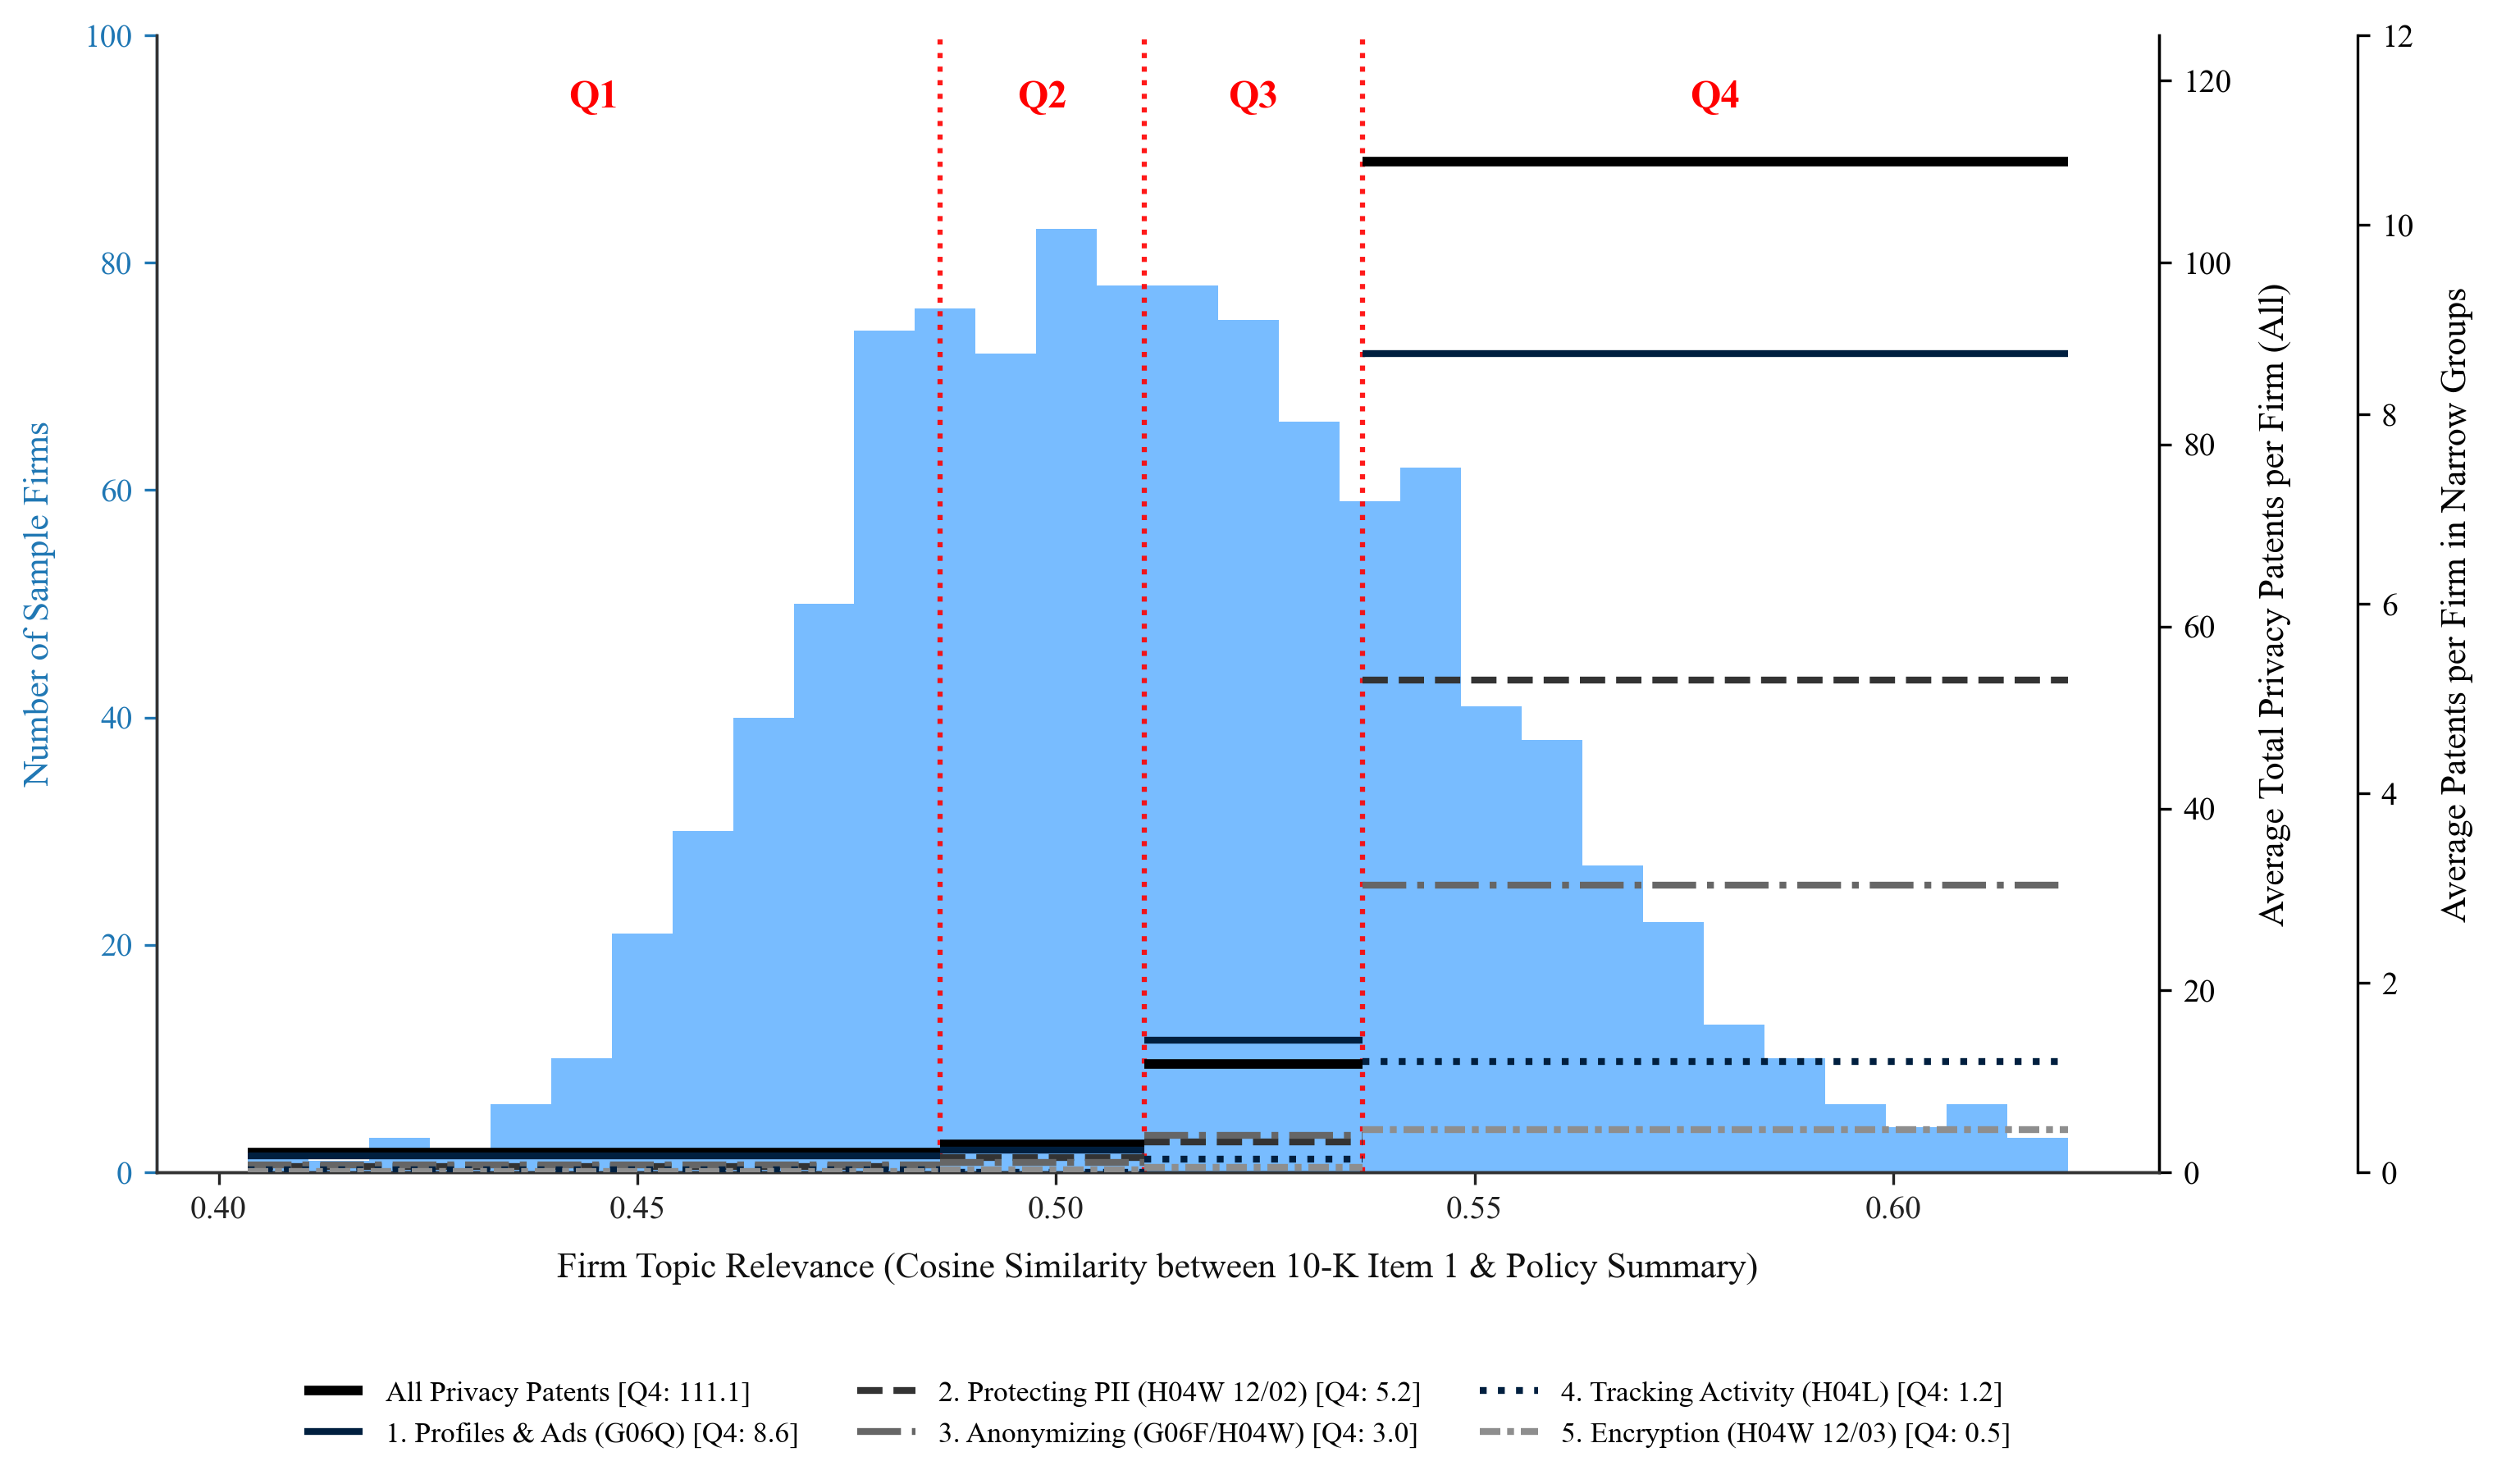

*Notes*: The histogram (dodger blue bars with no outlines on white background, left axis scaled 0–100) depicts the distribution of cosine similarity between firm-level 10-K Item 1 summaries and the policy summary across all 1,058 sample firms. Dotted vertical red lines mark quartile boundaries (Q1: ≤0.486, Q2: 0.486–0.511, Q3: 0.511–0.537, Q4: >0.537) with bold red labels positioned at the top. On the right, two separate black Y-axes illustrate patenting patterns across 6 categories using strictly black, grey, and navy lines with distinct styles: Right Axis 1 (scale 0–125) shows Total Privacy Patents (All, solid black), rising from 2.2 in Q1 to 111.1 in Q4. Right Axis 2 (scale 0–12, offset outward) shows the five narrow technology categories: Profiles & Ads (Q4: 8.6, navy solid), Protecting PII (Q4: 5.2, dark grey dashed), Anonymizing Data (Q4: 3.0, medium grey dash-dot), Tracking Activity (Q4: 1.2, navy dotted), and Encryption (Q4: 0.5, light grey dash-dot-dot). The frameless legend is positioned below the figure.

In [4]:
figure_name = "fig_1_topic_relevance_hist_with_patent_overlay"
figure_title = "Figure 1. Distribution of Firm Topic Relevance and Privacy Patents by Category Across Quartiles"

fig, ax1 = plt.subplots(figsize=(10.5, 6.0))
fig.patch.set_facecolor("#FFFFFF")
ax1.set_facecolor("#FFFFFF")

# 1. Left axis: Histogram of topic relevance (dodger blue, NO outlines, scale 0 to 100)
n_bins = 30
ax1.hist(
    df_firm["cosine_policy_summary_firm_summary"],
    bins=n_bins,
    color="dodgerblue",
    edgecolor="none",
    linewidth=0,
    alpha=0.60,
    zorder=2,
    label="Firm Topic Relevance Distribution"
)
ax1.set_xlabel("Firm Topic Relevance (Cosine Similarity between 10-K Item 1 & Policy Summary)", fontsize=10.5, labelpad=8)
ax1.set_ylabel("Number of Sample Firms", fontsize=10.5, color="#1F77B4", labelpad=8)
ax1.tick_params(axis="y", labelsize=9.5, colors="#1F77B4")
ax1.tick_params(axis="x", labelsize=9.5)
ax1.spines[["top"]].set_visible(False)
ax1.spines["left"].set_color("#1F77B4")
ax1.set_ylim(0, 100)

for b in q_bounds[1:-1]:
    ax1.axvline(b, color="red", linestyle=":", linewidth=1.5, alpha=0.9, zorder=3)

for q_i, q_name in enumerate(["Q1", "Q2", "Q3", "Q4"]):
    cx = (q_bounds[q_i] + q_bounds[q_i + 1]) / 2
    ax1.text(cx, 96, q_name, ha="center", va="top", fontsize=11.5, fontweight="bold", color="red", zorder=5)

# 2. Right Axis 1: Total Privacy Patents (All) - scale 0 to 125, Solid Black
ax2 = ax1.twinx()
ax2.set_facecolor("none")
ax2.spines[["top"]].set_visible(False)
ax2.spines["right"].set_color("#000000")

m_all = df_firm.groupby("quartile", observed=False)["patents_broad_all"].mean().values
for q_i in range(4):
    lbl = f"All Privacy Patents [Q4: {m_all[3]:.1f}]" if q_i == 0 else None
    ax2.hlines(m_all[q_i], q_bounds[q_i], q_bounds[q_i + 1], colors="#000000", linewidth=2.8, linestyle="-", label=lbl, zorder=6)

ax2.set_ylabel("Average Total Privacy Patents per Firm (All)", fontsize=10.5, color="#000000", labelpad=8)
ax2.tick_params(axis="y", labelsize=9.5, colors="#000000")
ax2.set_ylim(0, 125)

# 3. Right Axis 2: 5 Narrow Groups - black axis, scale 0 to 12
ax3 = ax1.twinx()
ax3.set_facecolor("none")
ax3.spines[["top"]].set_visible(False)
ax3.spines["right"].set_position(("outward", 58))
ax3.spines["right"].set_color("#000000")
ax3.tick_params(axis="y", labelsize=9.5, colors="#000000")
ax3.set_ylabel("Average Patents per Firm in Narrow Groups", fontsize=10.5, color="#000000", labelpad=8)
ax3.set_ylim(0, 12)

NAVY = "#001F3F"
DARK_GREY = "#333333"
MED_GREY = "#666666"
LIGHT_GREY = "#8E8E8E"

categories_spec = [
    ("patents_group_1", "1. Profiles & Ads (G06Q)", NAVY, "-"),
    ("patents_group_2", "2. Protecting PII (H04W 12/02)", DARK_GREY, "--"),
    ("patents_group_3", "3. Anonymizing (G06F/H04W)", MED_GREY, "-."),
    ("patents_group_5", "4. Tracking Activity (H04L)", NAVY, ":"),
    ("patents_group_4", "5. Encryption (H04W 12/03)", LIGHT_GREY, (0, (3, 1, 1, 1))),
]

for col, name, color, lstyle in categories_spec:
    m = df_firm.groupby("quartile", observed=False)[col].mean().values
    for q_i in range(4):
        lbl = f"{name} [Q4: {m[3]:.1f}]" if q_i == 0 else None
        ax3.hlines(m[q_i], q_bounds[q_i], q_bounds[q_i + 1], colors=color, linewidth=2.0, linestyle=lstyle, label=lbl, zorder=7)

h2, l2 = ax2.get_legend_handles_labels()
h3, l3 = ax3.get_legend_handles_labels()

ax1.legend(
    h2 + h3, l2 + l3,
    loc="upper center",
    bbox_to_anchor=(0.5, -0.16),
    ncol=3,
    frameon=False,
    fontsize=8.5
)

for ext in ["png", "svg", "pdf"]:
    fig.savefig(FIGURE_FOLDER / f"{figure_name}.{ext}", dpi=EXPORT_DPI, bbox_inches="tight")
    fig.savefig(FIGURE_FOLDER / f"1 - Figure 4 Panel A - Distribution of Firm Topic Relevance and Privacy Patents.{ext}", dpi=EXPORT_DPI, bbox_inches="tight")
plt.close(fig)

notes_fig1 = (
    "The histogram (dodger blue bars with no outlines on white background, left axis scaled 0–100) depicts the distribution of cosine similarity "
    "between firm-level 10-K Item 1 summaries and the policy summary across all 1,058 sample firms. Dotted vertical red lines mark quartile boundaries "
    "(Q1: ≤0.486, Q2: 0.486–0.511, Q3: 0.511–0.537, Q4: >0.537) with bold red labels positioned at the top. On the right, two separate black Y-axes "
    "illustrate patenting patterns across 6 categories using strictly black, grey, and navy lines with distinct styles: "
    "Right Axis 1 (scale 0–125) shows Total Privacy Patents (All, solid black), rising from 2.2 in Q1 to 111.1 in Q4. "
    "Right Axis 2 (scale 0–12, offset outward) shows the five narrow technology categories: "
    "Profiles & Ads (Q4: 8.6, navy solid), Protecting PII (Q4: 5.2, dark grey dashed), Anonymizing Data (Q4: 3.0, medium grey dash-dot), "
    "Tracking Activity (Q4: 1.2, navy dotted), and Encryption (Q4: 0.5, light grey dash-dot-dot). "
    "The frameless legend is positioned below the figure."
)
display(Markdown(f"**{figure_title}**"))
display(Image(filename=str(FIGURE_FOLDER / f"{figure_name}.png"), width=850))
display(Markdown(f"*Notes*: {notes_fig1}"))


## Step 5. Construct Pre- and Post-2016 panel dataset (2009–2020)

Restrict the patent data to the requested **2009 to 2020** period. Define Pre-2016 as 2009–2015 (7 years) and Post-2016 as 2016–2020 (5 years), computing annual patent rates and standard errors for each topic category, quartile, and decile.

In [5]:
# Restrict to 2009-2020 window
WINDOW_START, WINDOW_END = 2009, 2020
pats_win = df_patents[df_patents["filing_year"].between(WINDOW_START, WINDOW_END)].copy()

categories_dict = {
    "Tracking User Profiles and Data (G06Q)": (
        BLACK, "o", "-",
        pats_win[pats_win["privacy_cpc"].isin(["G06Q30/0269", "G06Q30/0255", "G06Q30/0261"])],
    ),
    "Protecting Privacy and Anonymity (PII) (H04W 12/02)": (
        BLUE, "s", "--",
        pats_win[pats_win["privacy_cpc"] == "H04W12/02"],
    ),
    "Anonymizing or Decorrelating Data (G06F/H04W)": (
        GREY, "^", "-.",
        pats_win[pats_win["privacy_cpc"].isin(["G06F21/6254", "H04W12/033"])],
    ),
    "Protecting Confidentiality by Encryption (H04W 12/03)": (
        CYAN, "D", ":",
        pats_win[pats_win["privacy_cpc"] == "H04W12/03"],
    ),
    "Tracking User Activity (H04L 67/535)": (
        MAROON, "v", (0, (3, 1, 1, 1)),
        pats_win[pats_win["privacy_cpc"] == "H04L67/535"],
    ),
}

# Construct period indicator
pats_win["period"] = np.where(pats_win["filing_year"] < 2016, "Pre", "Post")
pats_win_firm = pats_win.copy()


## Step 6. Figure 2: Privacy patent filings Pre- and Post-2016 across customer data and tracking subclasses

Point plot displaying annual patent filing rates before (2009–2015 average, in solid black) and after (2016–2020 average, in dodger blue) for each subclass of privacy patents related to handling customer data and tracking users.

**Figure 2. Change in Privacy Patent Filings Before and After 2016 by Subclass**

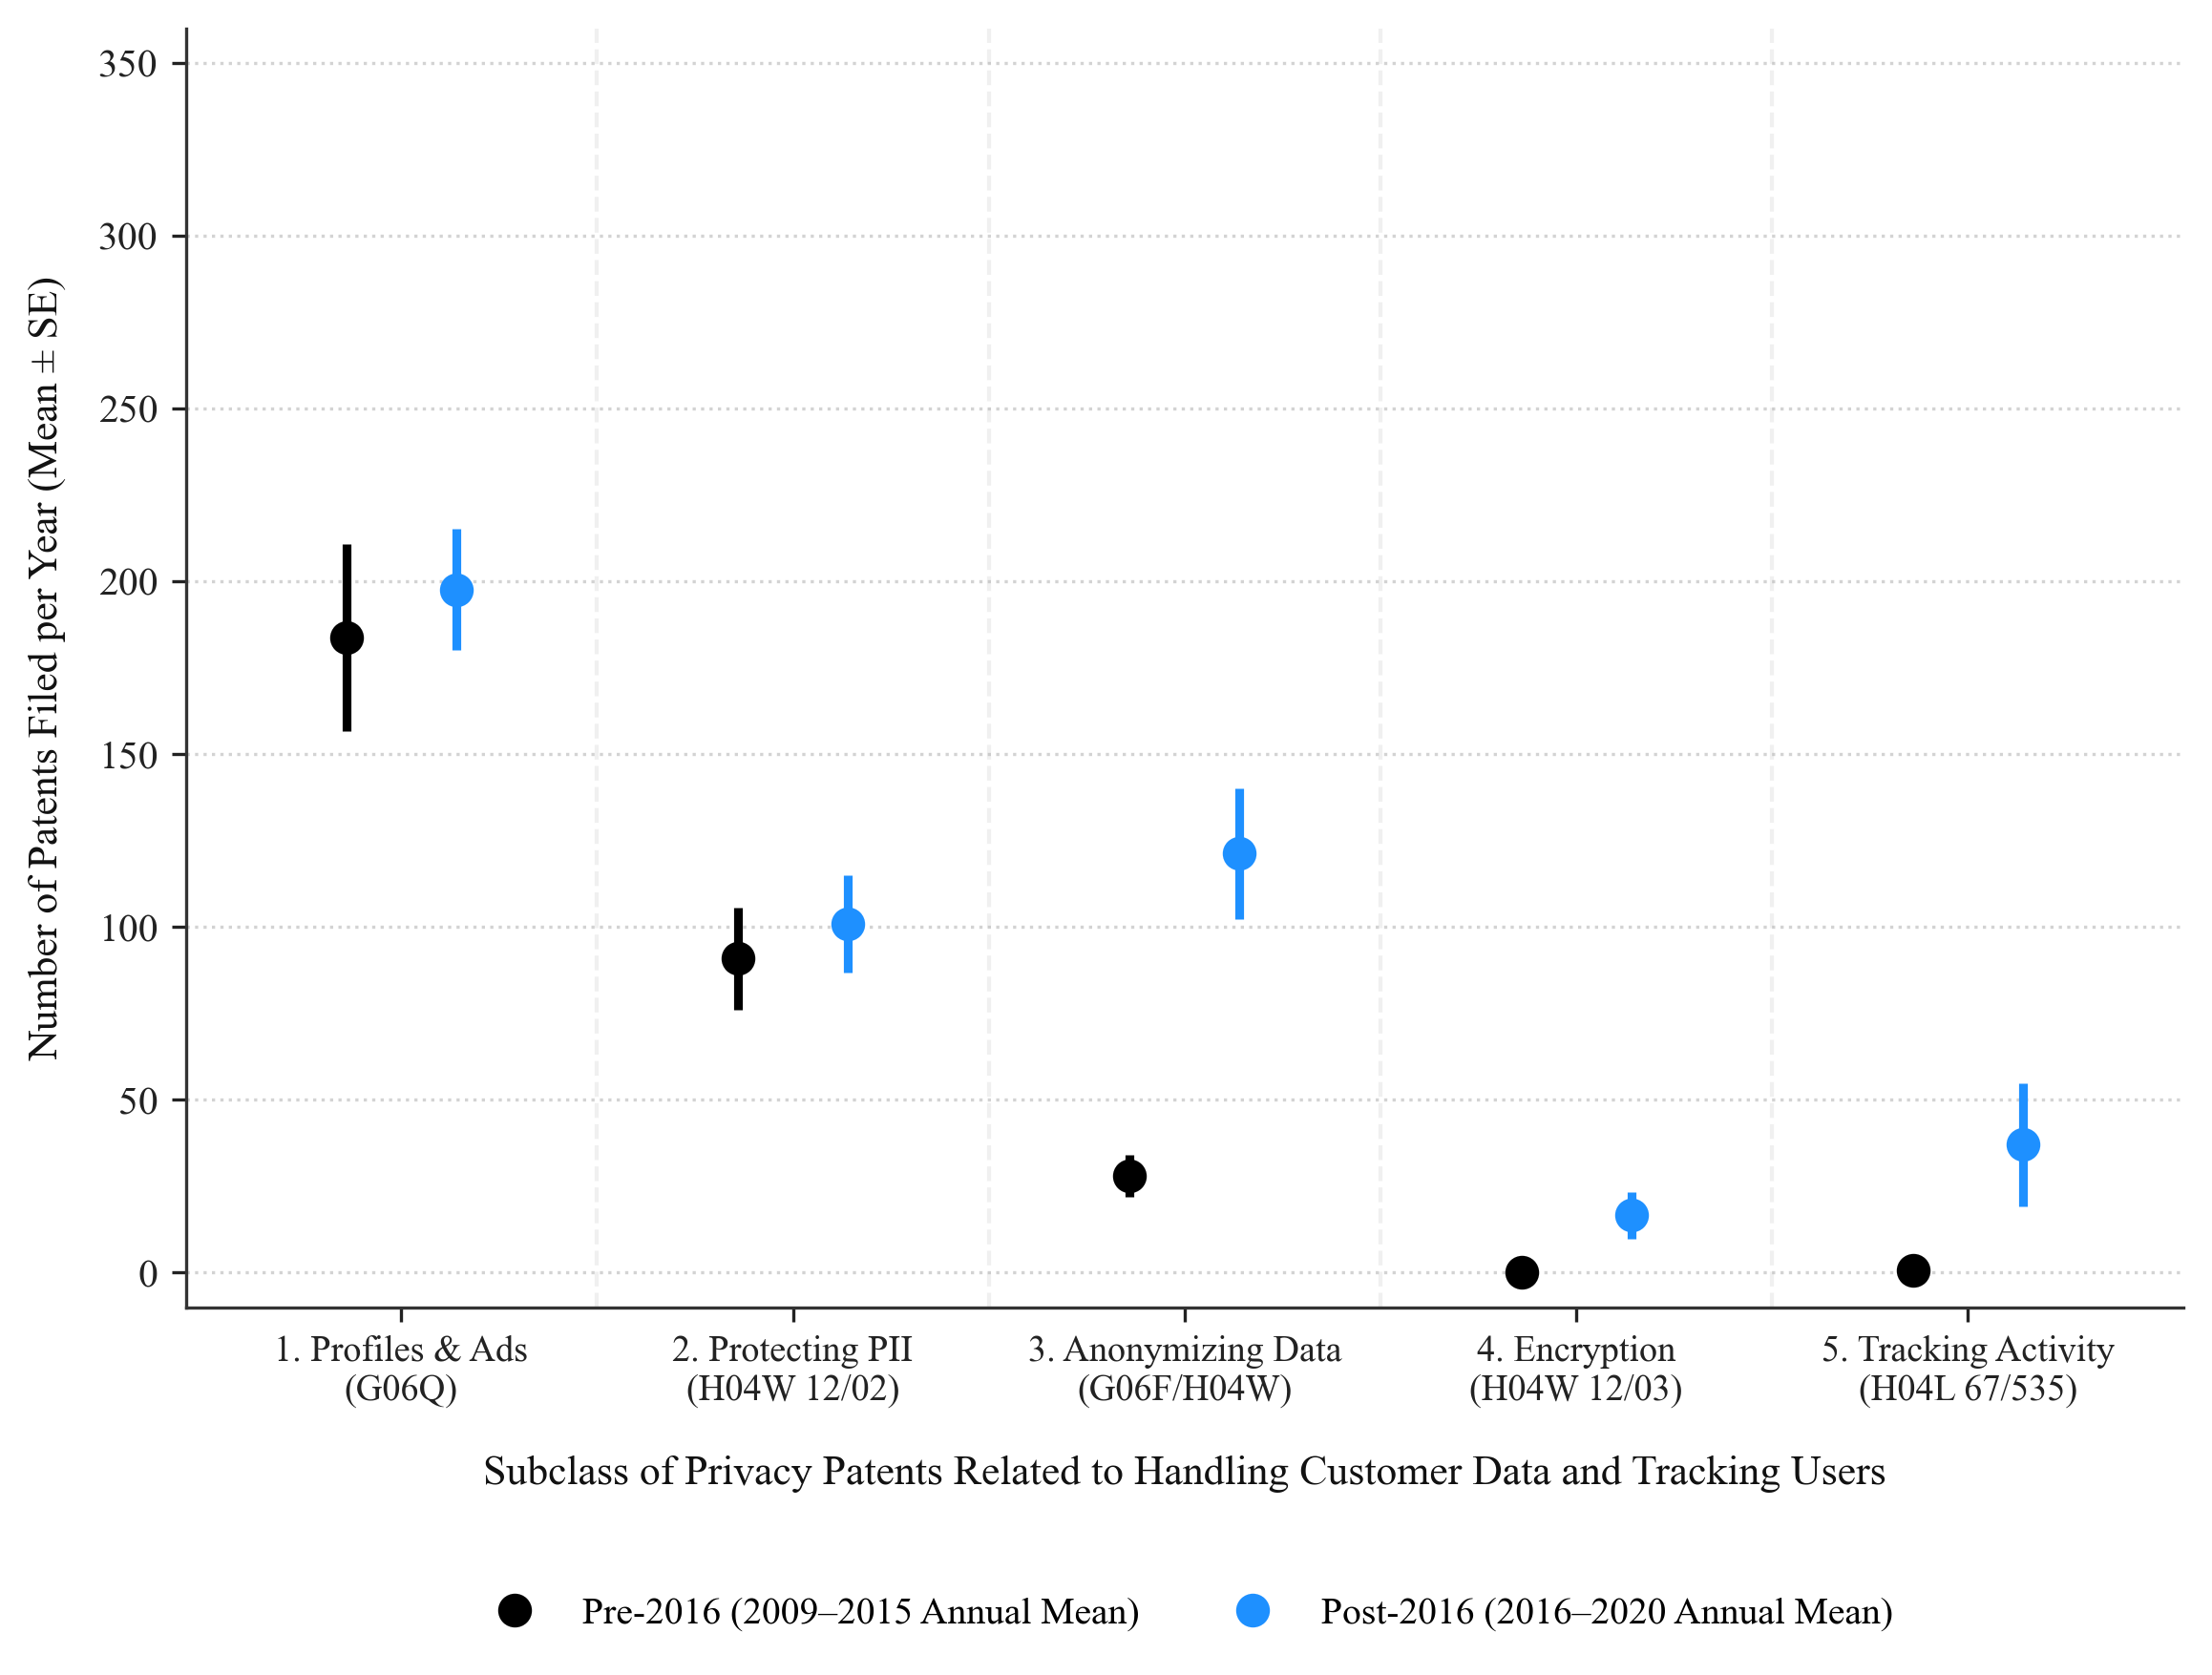

*Notes*: Annual privacy patent filings before (2009–2015, in black) versus after (2016–2020, in dodger blue) across the 5 subclasses related to handling customer data and tracking users. Filled circle markers without outlines and capless error bars represent annual mean ± standard error.

In [6]:
from matplotlib.lines import Line2D

figure_name = "fig_2_pointplot_pre_post_2016_narrow_groups"
figure_title = "Figure 2. Change in Privacy Patent Filings Before and After 2016 by Subclass"

point_estimates = []
for label, (color, marker, lstyle, subset) in categories_dict.items():
    sub = subset.copy()
    sub["period"] = np.where(sub["filing_year"] < 2016, "Pre", "Post")

    # Annual patent rates per year (7 pre years, 5 post years)
    pre_by_yr = sub[sub["period"] == "Pre"].groupby("filing_year")["patent_num"].nunique()
    post_by_yr = sub[sub["period"] == "Post"].groupby("filing_year")["patent_num"].nunique()

    pre_annual = [pre_by_yr.get(y, 0) for y in range(2009, 2016)]
    post_annual = [post_by_yr.get(y, 0) for y in range(2016, 2021)]

    pre_mean = np.mean(pre_annual)
    pre_se = np.std(pre_annual, ddof=1) / np.sqrt(len(pre_annual))

    post_mean = np.mean(post_annual)
    post_se = np.std(post_annual, ddof=1) / np.sqrt(len(post_annual))

    pct_change = ((post_mean - pre_mean) / pre_mean * 100) if pre_mean > 0 else np.nan

    point_estimates.append({
        "category": label,
        "pre_mean": pre_mean,
        "pre_se": pre_se,
        "post_mean": post_mean,
        "post_se": post_se,
        "diff": post_mean - pre_mean,
        "pct_change": pct_change,
    })

df_point = pd.DataFrame(point_estimates)
df_point.to_csv(TABLE_FOLDER / "pre_post_2016_pointplot_estimates_narrow_groups.csv", index=False)

fig, ax = plt.subplots(figsize=(FIGURE_WIDTH, FIGURE_HEIGHT))
fig.patch.set_facecolor("#FFFFFF")
ax.set_facecolor("#FFFFFF")

c_pre = "#000000"       # Black
c_post = "dodgerblue"   # Dodger Blue

offset = 0.14

for idx, r in df_point.iterrows():
    x_pos = idx
    # Pre-2016: Black, circle, filled in, no outline, no caps
    ax.errorbar(
        x_pos - offset,
        r["pre_mean"],
        yerr=r["pre_se"],
        fmt="o",
        color=c_pre,
        ecolor=c_pre,
        elinewidth=2.2,
        capsize=0,
        markersize=8.5,
        markeredgewidth=0,
        zorder=4,
    )
    # Post-2016: Dodger Blue, circle, filled in, no outline, no caps
    ax.errorbar(
        x_pos + offset,
        r["post_mean"],
        yerr=r["post_se"],
        fmt="o",
        color=c_post,
        ecolor=c_post,
        elinewidth=2.2,
        capsize=0,
        markersize=8.5,
        markeredgewidth=0,
        zorder=4,
    )
    if idx < len(df_point) - 1:
        ax.axvline(idx + 0.5, color="#F0F0F0", linestyle="--", linewidth=1.0, zorder=1)

short_labels = [
    "1. Profiles & Ads\n(G06Q)",
    "2. Protecting PII\n(H04W 12/02)",
    "3. Anonymizing Data\n(G06F/H04W)",
    "4. Encryption\n(H04W 12/03)",
    "5. Tracking Activity\n(H04L 67/535)",
]

ax.set_xticks(range(len(short_labels)))
ax.set_xticklabels(short_labels, fontsize=9.2, weight="medium")
ax.set_xlim(-0.55, len(short_labels) - 0.45)
ax.set_ylim(-10, 360)

ax.set_xlabel("Subclass of Privacy Patents Related to Handling Customer Data and Tracking Users", fontsize=10.5, labelpad=12)
ax.set_ylabel("Number of Patents Filed per Year (Mean ± SE)", fontsize=10.5, labelpad=8)
ax.grid(axis="y", linestyle=":", alpha=0.55, zorder=0)
ax.spines[["top", "right"]].set_visible(False)

legend_elements = [
    Line2D([0], [0], marker="o", color="w", label="Pre-2016 (2009–2015 Annual Mean)",
           markerfacecolor=c_pre, markeredgewidth=0, markersize=8.5),
    Line2D([0], [0], marker="o", color="w", label="Post-2016 (2016–2020 Annual Mean)",
           markerfacecolor=c_post, markeredgewidth=0, markersize=8.5),
]
ax.legend(
    handles=legend_elements,
    loc="upper center",
    bbox_to_anchor=(0.5, -0.20),
    ncol=2,
    frameon=False,
    fontsize=9.5,
)

for ext in ["png", "svg", "pdf"]:
    fig.savefig(FIGURE_FOLDER / f"{figure_name}.{ext}", dpi=EXPORT_DPI, bbox_inches="tight")
    fig.savefig(FIGURE_FOLDER / f"3 - Figure 4 Panel C - Annual Privacy Patent Filings by Subclass.{ext}", dpi=EXPORT_DPI, bbox_inches="tight")
plt.close(fig)

notes_fig2 = (
    "Annual privacy patent filings before (2009–2015, in black) versus after (2016–2020, in dodger blue) "
    "across the 5 subclasses related to handling customer data and tracking users. "
    "Filled circle markers without outlines and capless error bars represent annual mean ± standard error."
)
display(Markdown(f"**{figure_title}**"))
display(Image(filename=str(FIGURE_FOLDER / f"{figure_name}.png"), width=850))
display(Markdown(f"*Notes*: {notes_fig2}"))


## Step 7. Figure 3: Privacy patent filings Pre- and Post-2016 across firm topic relevance quartiles

Point plot displaying firm-level annual privacy patent filings before (2009–2015 average, in solid black) and after (2016–2020 average, in dodger blue) clustered by firm topic relevance quartile ($Q_1$ to $Q_4$), strictly adopting the themes, colors, capless error bars, and frameless legend of Figure 2.

**Figure 3. Privacy Patenting Before and After 2016 Across Firm Topic Relevance Quartiles**

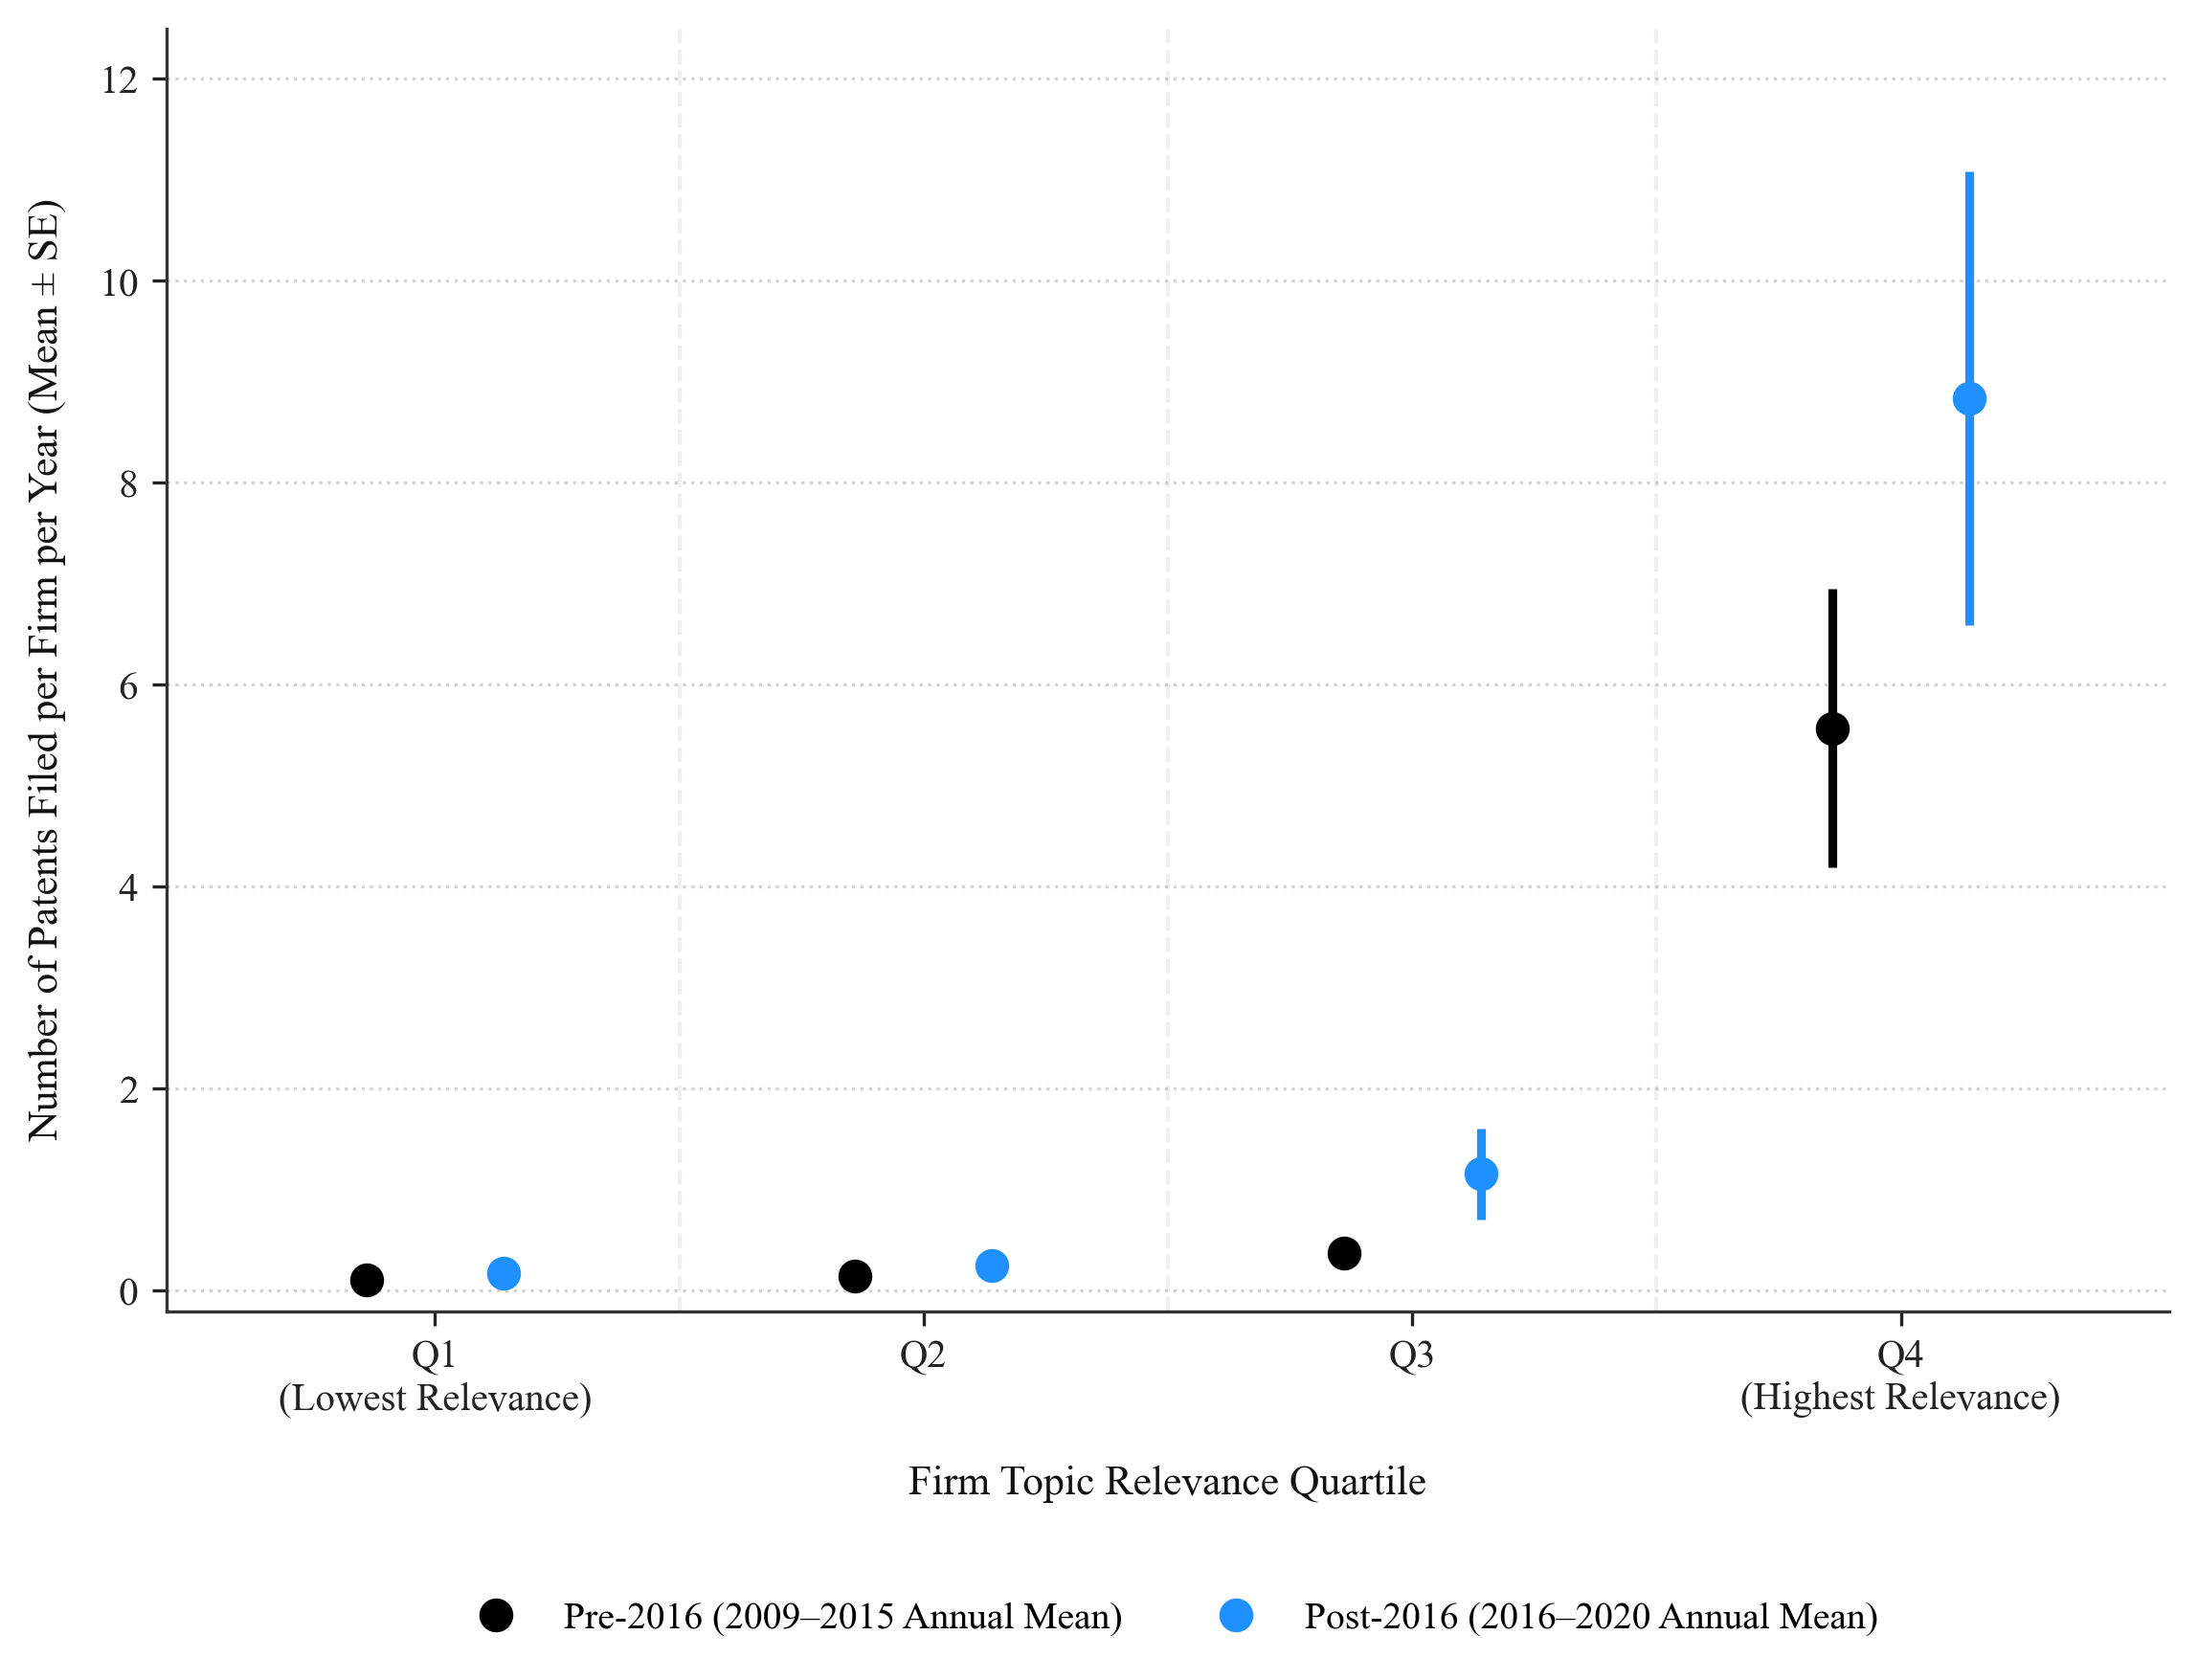

*Notes*: Firm-level annual privacy patent rate before (2009–2015, in black) versus after (2016–2020, in dodger blue) clustered by topic relevance quartile along the X-axis, strictly applying the theme of Figure 2. Points are filled circles with no outline and capless standard error bars (`capsize=0`). Firms in Q4 drove the patent surge, rising from 5.57 patents/yr/firm pre-2016 to 8.84 post-2016 (+3.27/yr/firm).

In [7]:
from matplotlib.lines import Line2D

figure_name = "fig_3_pointplot_by_relevance_quartile"
figure_title = "Figure 3. Privacy Patenting Before and After 2016 Across Firm Topic Relevance Quartiles"

q_pre_post = []
for q_lbl in ["Q1 (Lowest Relevance)", "Q2", "Q3", "Q4 (Highest Relevance)"]:
    q_gvkeys = df_firm.loc[df_firm["quartile"] == q_lbl, "gvkey"].unique()
    pre_sub = pats_win_firm[(pats_win_firm["gvkey"].isin(q_gvkeys)) & (pats_win_firm["period"] == "Pre")]
    post_sub = pats_win_firm[(pats_win_firm["gvkey"].isin(q_gvkeys)) & (pats_win_firm["period"] == "Post")]

    pre_firm_counts = pre_sub.groupby("gvkey")["patent_num"].nunique().reindex(q_gvkeys, fill_value=0) / 7.0
    post_firm_counts = post_sub.groupby("gvkey")["patent_num"].nunique().reindex(q_gvkeys, fill_value=0) / 5.0

    q_pre_post.append({
        "quartile": q_lbl,
        "pre_mean": pre_firm_counts.mean(),
        "pre_se": pre_firm_counts.sem(),
        "post_mean": post_firm_counts.mean(),
        "post_se": post_firm_counts.sem(),
        "change": post_firm_counts.mean() - pre_firm_counts.mean(),
    })

df_q_point = pd.DataFrame(q_pre_post)
df_q_point.to_csv(TABLE_FOLDER / "pre_post_by_relevance_quartile.csv", index=False)

fig, ax = plt.subplots(figsize=(FIGURE_WIDTH, FIGURE_HEIGHT))
fig.patch.set_facecolor("#FFFFFF")
ax.set_facecolor("#FFFFFF")

c_pre = "#000000"
c_post = "dodgerblue"

q_short_labels = ["Q1\n(Lowest Relevance)", "Q2", "Q3", "Q4\n(Highest Relevance)"]
offset = 0.14

for idx, r in df_q_point.iterrows():
    x_pos = idx
    ax.errorbar(
        x_pos - offset, r["pre_mean"], yerr=r["pre_se"],
        fmt="o", color=c_pre, ecolor=c_pre, elinewidth=2.2, capsize=0,
        markersize=8.5, markeredgewidth=0, zorder=4
    )
    ax.errorbar(
        x_pos + offset, r["post_mean"], yerr=r["post_se"],
        fmt="o", color=c_post, ecolor=c_post, elinewidth=2.2, capsize=0,
        markersize=8.5, markeredgewidth=0, zorder=4
    )
    if idx < len(df_q_point) - 1:
        ax.axvline(idx + 0.5, color="#F0F0F0", linestyle="--", linewidth=1.0, zorder=1)

ax.set_xticks(range(len(q_short_labels)))
ax.set_xticklabels(q_short_labels, fontsize=9.8, weight="medium")
ax.set_xlim(-0.55, len(q_short_labels) - 0.45)
ax.set_ylim(-0.2, 12.5)

ax.set_xlabel("Firm Topic Relevance Quartile", fontsize=10.5, labelpad=12)
ax.set_ylabel("Number of Patents Filed per Firm per Year (Mean ± SE)", fontsize=10.5, labelpad=8)
ax.grid(axis="y", linestyle=":", alpha=0.55, zorder=0)
ax.spines[["top", "right"]].set_visible(False)

legend_elements = [
    Line2D([0], [0], marker="o", color="w", label="Pre-2016 (2009–2015 Annual Mean)",
           markerfacecolor=c_pre, markeredgewidth=0, markersize=8.5),
    Line2D([0], [0], marker="o", color="w", label="Post-2016 (2016–2020 Annual Mean)",
           markerfacecolor=c_post, markeredgewidth=0, markersize=8.5),
]
ax.legend(
    handles=legend_elements, loc="upper center", bbox_to_anchor=(0.5, -0.20),
    ncol=2, frameon=False, fontsize=9.5
)

for ext in ["png", "svg", "pdf"]:
    fig.savefig(FIGURE_FOLDER / f"{figure_name}.{ext}", dpi=EXPORT_DPI, bbox_inches="tight")
    fig.savefig(FIGURE_FOLDER / f"2 - Figure 4 Panel B - Annual Privacy Patent Filings by Relevance Quartile.{ext}", dpi=EXPORT_DPI, bbox_inches="tight")
plt.close(fig)

notes_fig3 = (
    "Firm-level annual privacy patent rate before (2009–2015, in black) versus after (2016–2020, in dodger blue) "
    "clustered by topic relevance quartile along the X-axis, strictly applying the theme of Figure 2. "
    "Points are filled circles with no outline and capless standard error bars (`capsize=0`). "
    "Firms in Q4 drove the patent surge, rising from 5.57 patents/yr/firm pre-2016 to 8.84 post-2016 (+3.27/yr/firm)."
)
display(Markdown(f"**{figure_title}**"))
display(Image(filename=str(FIGURE_FOLDER / f"{figure_name}.png"), width=850))
display(Markdown(f"*Notes*: {notes_fig3}"))
